In [61]:
from f1strategy.data import load_season
from f1strategy.simulator import simulate_strategy, Strategy, Stint, get_race_lengths
from f1strategy.degradation import fit, training_testing_split, FORMULA
from f1strategy.strategy import lookup_table, score_strategy, best_strategy, actual_strategies
from f1strategy.data import FIGURES_DIR

import pandas as pd
import collections

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

In [19]:
clean_data, raw_data = load_season(2025)

In [20]:
training_data, testing_data = training_testing_split(clean_data)

In [21]:
model = fit(training_data, FORMULA)

#### Simulator Checks

In [22]:
race_lengths = get_race_lengths(raw_data)
race_lengths

{'Abu Dhabi Grand Prix': 58,
 'Austrian Grand Prix': 70,
 'Azerbaijan Grand Prix': 51,
 'Bahrain Grand Prix': 57,
 'Canadian Grand Prix': 70,
 'Chinese Grand Prix': 56,
 'Dutch Grand Prix': 72,
 'Emilia Romagna Grand Prix': 63,
 'Hungarian Grand Prix': 70,
 'Italian Grand Prix': 53,
 'Japanese Grand Prix': 53,
 'Las Vegas Grand Prix': 50,
 'Mexico City Grand Prix': 71,
 'Miami Grand Prix': 57,
 'Monaco Grand Prix': 78,
 'Qatar Grand Prix': 57,
 'Saudi Arabian Grand Prix': 50,
 'Singapore Grand Prix': 62,
 'Spanish Grand Prix': 66,
 'São Paulo Grand Prix': 71,
 'United States Grand Prix': 56}

In [23]:
#Check a one stop at Abu Dhabi
strategy = Strategy([Stint('MEDIUM', 28), Stint('HARD', 30)])
circuit = "Abu Dhabi Grand Prix"

total_time = simulate_strategy(strategy, model, circuit, "ALB", race_lengths[circuit])
total_time

5226.971001026298

In [24]:
#Check a different one stop strategy at Abu Dhabi
strategy = Strategy([Stint('MEDIUM', 20), Stint('HARD', 38)])
circuit = "Abu Dhabi Grand Prix"

total_time = simulate_strategy(strategy, model, circuit, "ALB", race_lengths[circuit])
total_time

5230.230374133568

In [25]:
#Try an invalid strategy
strategy = Strategy([Stint('HARD', 20), Stint('HARD', 38)])
circuit = "Abu Dhabi Grand Prix"

try:
    total_time = simulate_strategy(strategy, model, circuit, "ALB", race_lengths[circuit])
    print(total_time)
except Exception as e:
    print(f"Error: {e}")

Error: The strategy must use at least two different tyre compounds.


#### Strategy Checks

In [26]:
table = lookup_table("ALB", circuit, race_lengths[circuit], model)

strategy = Strategy(stints=[
    Stint("MEDIUM", 28),
    Stint("HARD", 30)
])

score_strategy(strategy, table)

5226.971001026296

In [27]:
#Run a full strategy evaluation on Albon at Abu Dhabi
best_strategies, num_strategies_checked = best_strategy(table, race_lengths[circuit])

In [28]:
best_strategy_test = best_strategies[0]
best_5_strategies = best_strategies[:5]

print(best_strategy_test)
print(f"Number of strategies checked: {num_strategies_checked}")
print("Best 5 strategies:")
for strategy in best_5_strategies:
    print(strategy)

(5226.953334405552, Strategy(stints=[Stint(compound='MEDIUM', laps=29), Stint(compound='HARD', laps=29)]))
Number of strategies checked: 9890
Best 5 strategies:
(5226.953334405552, Strategy(stints=[Stint(compound='MEDIUM', laps=29), Stint(compound='HARD', laps=29)]))
(5226.953334405552, Strategy(stints=[Stint(compound='HARD', laps=29), Stint(compound='MEDIUM', laps=29)]))
(5226.971001026296, Strategy(stints=[Stint(compound='MEDIUM', laps=28), Stint(compound='HARD', laps=30)]))
(5226.971001026297, Strategy(stints=[Stint(compound='HARD', laps=30), Stint(compound='MEDIUM', laps=28)]))
(5227.024983838414, Strategy(stints=[Stint(compound='MEDIUM', laps=30), Stint(compound='HARD', laps=28)]))


#### Search results at Abu Dhabi

The search checked 9890 valid one and two stop strategies. The best was medium for 29 laps then hard for 29, at 5226.95 seconds.

- Stint order does not matter to the model. Medium then hard gives the exact same time as hard then medium, because fuel is its own term and each stint's tyre age always starts at 1 no matter where it falls in the race.
- The top 5 strategies are within 0.07 seconds of each other, which is much smaller than the model's error. The model is confident about using one stop on medium and hard, but the exact pit lap is basically a tie.

In [29]:
#Look at real strategies used by drivers at the Abu Dhabi Grand Prix
race = "Abu Dhabi Grand Prix"
strategies, skipped = actual_strategies(raw_data, race)

print(len(strategies))
print(skipped)

#Print the strategies for each driver
for driver, strategy in strategies.items():
    print(driver, strategy)

16
4
VER MEDIUM stint for 23 laps -> HARD stint for 35 laps
PIA HARD stint for 41 laps -> MEDIUM stint for 17 laps
NOR MEDIUM stint for 16 laps -> HARD stint for 24 laps -> HARD stint for 18 laps
LEC MEDIUM stint for 16 laps -> HARD stint for 23 laps -> MEDIUM stint for 19 laps
RUS MEDIUM stint for 14 laps -> HARD stint for 44 laps
ALO MEDIUM stint for 16 laps -> HARD stint for 42 laps
OCO MEDIUM stint for 19 laps -> HARD stint for 39 laps
HAM SOFT stint for 8 laps -> HARD stint for 23 laps -> MEDIUM stint for 27 laps
HUL SOFT stint for 7 laps -> HARD stint for 35 laps -> MEDIUM stint for 16 laps
STR HARD stint for 42 laps -> MEDIUM stint for 16 laps
BOR MEDIUM stint for 15 laps -> HARD stint for 43 laps
BEA MEDIUM stint for 14 laps -> HARD stint for 44 laps
SAI MEDIUM stint for 18 laps -> HARD stint for 40 laps
TSU HARD stint for 32 laps -> MEDIUM stint for 26 laps
ANT HARD stint for 32 laps -> MEDIUM stint for 26 laps
ALB SOFT stint for 8 laps -> HARD stint for 25 laps -> MEDIUM stin

In [30]:
#Score the actual strategies used by drivers at the Abu Dhabi Grand Prix
#We put "ALB" as the driver for all simulations because the optimal from above was only calulated for Albon
#With our model, each driver gets a certain offset that only shifts everything up or down, so simulating all drivers as "ALB" is a reasonable approximation for comparison to our optimal
for driver, strategy in strategies.items():
    try:
        score = simulate_strategy(strategy, model, race, "ALB", race_lengths[race])
        print(f"{driver}: {score}")
    except Exception as e:
        print(f"Error simulating strategy for {driver}: {e}")

VER: 5228.370684745816
PIA: 5232.82820499647
NOR: 5234.074696738668
LEC: 5235.305499370461
RUS: 5236.142276332078
ALO: 5233.854394697912
OCO: 5231.015383566058
HAM: 5238.7744565964695
HUL: 5243.243463774676
STR: 5233.854394697912
BOR: 5234.959355525861
BEA: 5236.142276332078
SAI: 5231.881597569773
TSU: 5227.271037835664
ANT: 5227.271037835664
ALB: 5238.574086808537


#### Best strategies vs. real strategies across 10 races.

In [67]:
#We already only have dry races, so we just need to exclude Qatar and Monaco
#This is because Monaco requires two stops and Qatar had a maximum stint lenth of 25 laps
#We want to focus on races where a one-stop strategy is feasible
#We also remove Canada and Miama because of incomplete or bad data from the API
selected_races = [race for race in race_lengths if race not in {"Qatar Grand Prix", "Monaco Grand Prix", "Canadian Grand Prix", "Miami Grand Prix"}]

In [68]:
race_results = {}

for race in selected_races:
    delta_simulated_actual = {}
    drivers_kept = []
    drivers_dropped = []

    race_length = race_lengths[race]
    table = lookup_table("ALB", race, race_length, model)

    best_strategies, num_checked = best_strategy(table, race_length)
    best_time = best_strategies[0][0]
    optimal_strategy = best_strategies[0][1]

    real_strategies, skipped = actual_strategies(raw_data, race)
    
    for driver, strategy in real_strategies.items():
        try:
            simulated_time = simulate_strategy(strategy, model, race, "ALB", race_length)
            delta_simulated_actual[driver] = simulated_time - best_time
            drivers_kept.append(driver)
        except Exception as e:
            drivers_dropped.append(driver)
            print(f"Error simulating strategy for {driver}: {e}")
    
    race_results[race] = {
        "deltas": delta_simulated_actual,
        "optimal": optimal_strategy,
        "actual": real_strategies,
        "kept": drivers_kept,
        "dropped": drivers_dropped,
        "skipped": skipped,
        "num_checked": num_checked,
        "best_time": best_time
    }

#### Make a table to display our per race results in a comprehensible way

In [69]:
races = []
optimal_strategies = []
most_common_actual_strategies = []
average_deltas = []
number_of_drivers_kept = []
number_of_drivers_dropped = []
number_of_strategies_checked = []
best_times = []

def most_common_actual_strategy(real_strategies: dict[str, Strategy], finished_drivers:list[str]):
    #We only care about the list of ordered compounds used in the actual strategies
    compounds = []
    for driver in finished_drivers:
        strategy = real_strategies[driver]
        order_compounds = []
        for stint in strategy.stints:
            order_compounds.append(stint.compound)
        compounds.append(tuple(order_compounds))

    order, count = collections.Counter(compounds).most_common(1)[0]
    return f"{' → '.join(order)} ({count} of {len(finished_drivers)})"

def compact_strategy(strategy: Strategy) -> str:
    #Shorten each stint to compound letter and laps, for example M23 -> H35
    return " → ".join(f"{stint.compound[0]}{stint.laps}" for stint in strategy.stints)

for race in race_results.keys():
    races.append(race)
    results = race_results[race]

    optimal_strategies.append(compact_strategy(results['optimal']))
    most_common_actual_strategies.append(most_common_actual_strategy(results['actual'], results['kept']))
    average_deltas.append(sum(results['deltas'].values()) / len(results['deltas']))
    number_of_drivers_kept.append(len(results['kept']))
    number_of_drivers_dropped.append(len(results['dropped']) + results['skipped'])
    number_of_strategies_checked.append(results['num_checked'])
    best_times.append(results['best_time'])

race_table = pd.DataFrame({
    'Race': races,
    'Optimal Strategy': optimal_strategies,
    'Most Common Actual Strategy': most_common_actual_strategies,
    'Average Delta': average_deltas,
    'Number of Drivers Kept': number_of_drivers_kept,
    'Number of Drivers Dropped': number_of_drivers_dropped,
    'Number of Strategies Checked': number_of_strategies_checked,
    'Best Time': best_times
})

race_table

,Race,Optimal Strategy,Most Common Actual Strategy,Average Delta,Number of Drivers Kept,Number of Drivers Dropped,Number of Strategies Checked,Best Time
0,Abu Dhabi Grand Prix,M29 → H29,MEDIUM → HARD (7 of 16),7.019344,16,4,9890,5226.953334
1,Austrian Grand Prix,M23 → H23 → H24,MEDIUM → HARD → MEDIUM (4 of 6),4.603131,6,13,7662,4988.717124
2,Azerbaijan Grand Prix,S8 → H43,MEDIUM → HARD (8 of 17),4.124324,17,3,9510,5445.799667
3,Bahrain Grand Prix,S18 → H20 → H19,SOFT → MEDIUM → HARD (5 of 19),8.041387,19,1,9930,5653.272124
4,Chinese Grand Prix,M27 → H29,MEDIUM → HARD (11 of 16),4.140591,16,4,9946,5508.111522
5,Dutch Grand Prix,H24 → M24 → H24,MEDIUM → HARD → SOFT (4 of 17),9.490915,17,3,7109,5497.606458
6,Emilia Romagna Grand Prix,H32 → M31,MEDIUM → HARD → HARD (11 of 18),7.225687,18,2,9332,5165.128699
7,Hungarian Grand Prix,M32 → H38,MEDIUM → HARD (5 of 9),1.597501,9,11,7662,5795.230366
8,Italian Grand Prix,H37 → S16,MEDIUM → HARD (9 of 14),1.104432,14,5,9796,4455.480123
9,Japanese Grand Prix,S18 → H35,MEDIUM → HARD (13 of 19),0.603809,19,1,9796,4973.401570


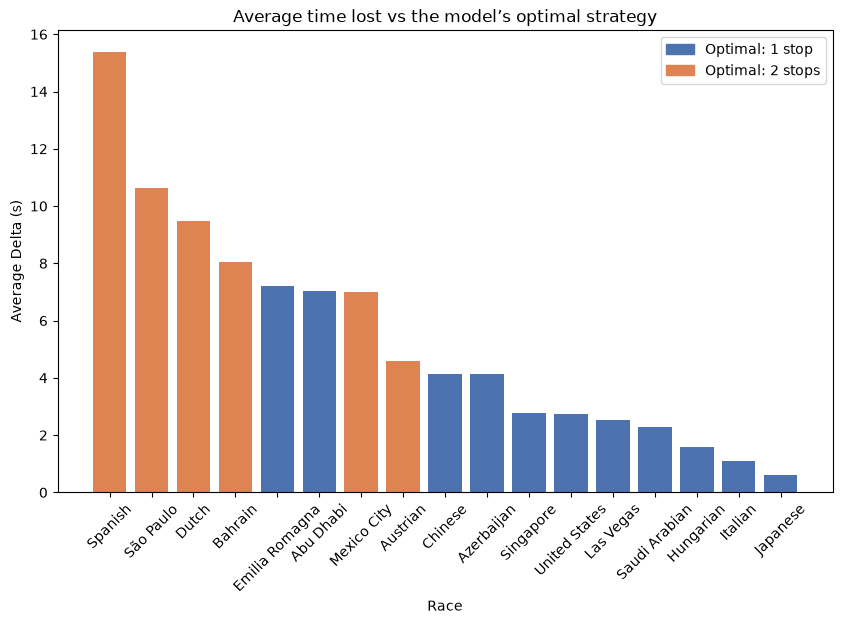

In [70]:
#Bar chart of Average Delta per Race, colored by the number of stops in the optimal strategy

race_table_sorted = race_table.sort_values(by='Average Delta', ascending=False)

stop_colors = {1: "#4C72B0", 2: "#DD8452"}
bar_colors = [stop_colors[s.count("→")] for s in race_table_sorted["Optimal Strategy"]]
short_names = race_table_sorted["Race"].str.replace(" Grand Prix", "")

plt.figure(figsize=(10, 6))
plt.bar(short_names, race_table_sorted["Average Delta"], color=bar_colors)
plt.legend(handles=[Patch(color=stop_colors[1], label="Optimal: 1 stop"),
                    Patch(color=stop_colors[2], label="Optimal: 2 stops")])

plt.xlabel('Race')
plt.ylabel('Average Delta (s)')
plt.title('Average time lost vs the model’s optimal strategy')
plt.xticks(rotation=45)

plt.savefig(FIGURES_DIR / "average_delta_by_race.png", bbox_inches='tight', dpi=300)
plt.show()

#### Counterfactual results

S, M and H in the table stand for soft, medium and hard.

- The model chose two stops at Bahrain, Austria, Spain and São Paulo and one stop everywhere else. This matches the circuit wear ranking, so high wear tracks get more stops.
- Deltas are small at low wear tracks like Japan, Monza and Hungary, where the model mostly agrees with the teams, and large at high wear tracks like Spain, São Paulo and Bahrain.
- Spain has the largest delta. Many drivers ended on two soft stints in a row, which usually means a late safety car stop that cost much less than the 20 seconds the model charges.
- The compounds the model picks come from the backwards baselines. It thinks hard is fastest, so at low wear tracks it runs hard as long as allowed and adds a short soft stint just to use two compounds. Most teams ran medium then hard.
- Austria and Hungary drop more than half the field because lapped cars never finish the full 70 laps, so those rows only cover the front runners.
- Qatar and Monaco were left out because of their 2025 rules.#### Counterfactual results

S, M and H in the table stand for soft, medium and hard. The search was run on 17 of the 21 dry races.

- The model chose two stops at Austria, Bahrain, Mexico City, Spain, São Paulo and the Dutch Grand Prix and one stop everywhere else. The first five are the five highest wear tracks in the circuit ranking, and the Dutch Grand Prix is the longest race at 72 laps.
- All six two stop races are in the top eight average deltas. The low wear one stop races like Japan, Monza and Hungary have the smallest deltas, so the model mostly agrees with the teams there.
- Spain has the largest delta. Many drivers ended on two soft stints in a row, which usually means a late safety car stop that cost much less than the 20 seconds the model charges.
- Imola and Abu Dhabi have high deltas for one stop races because several drivers actually stopped twice.
- The compounds the model picks come from the backwards baselines. It thinks hard is fastest, so at low wear tracks it runs hard as long as allowed and adds a short soft stint just to use two compounds. Most teams ran medium then hard.
- Austria, Hungary and Singapore keep fewer drivers because lapped cars never finish the full distance, so those rows mostly cover the front runners.
- Qatar and Monaco were left out because of their 2025 rules. Canada was left out because its stint data looks broken, with many drivers showing five or six stints. Miami was left out because only 2 drivers had full tyre data.

#### Future improvements

**Model**
- Add an interaction between tyre age and driver so the model can learn how well each driver and car manage their tyres
- Let each compound wear at its own rate at each circuit, and let the tyre curve shape change by circuit
- Account for traffic and opening lap effects, which would likely fix the backwards compound baselines
- Separate fuel burn from track evolution instead of letting lap number capture both
- Try a small neural network or gradient boosting on the same split and compare against OLS
- Use a robust regression or handle outlier laps from traffic and mistakes
- Use standard errors that account for laps in the same stint being related

**Search and simulator**
- Measure pit loss for each circuit instead of using 20 seconds everywhere
- Model safety cars, virtual safety cars and red flags, since cheap stops under caution are the main reason teams leave the plan
- Include three stop strategies and use the state space search to keep it fast
- Start each race on the actual starting tyre age instead of assuming fresh tyres
- Add special race rules such as the Qatar stint limit and the Monaco two stop rule so those races can be included
- Capture effects that make stint order matter

**Data**
- Use more seasons from the same regulation era with year as a feature
- Include wet races and the intermediate and wet compounds
- Add track temperature and weather
- Use the actual Pirelli compound at each race instead of the relative soft, medium and hard labels